# ЛР 1 - линейная и логистическая регрессия

> Выполнил: Карнажицкий Максим Романович (466127), P3311

## Импорты и воспроизводимость

Зафиксируем seed и долю тестовой выборки

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SEED = 67
TEST_SIZE = 0.2

# Часть A. Линейная регрессия

## Загрузка и первичное исследование данных

одна строка - один день; `cnt` - общее число аренд.

In [3]:
df = pd.read_csv("data/day.csv", parse_dates=["dteday"])

print("Размер:", df.shape)
df.head()

Размер: (731, 16)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


### Структура, типы и пропуски

Посмотрим типы и пропуски

In [4]:
df.info()
df.isna().sum()

<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     731 non-null    int64         
 1   dteday      731 non-null    datetime64[us]
 2   season      731 non-null    int64         
 3   yr          731 non-null    int64         
 4   mnth        731 non-null    int64         
 5   holiday     731 non-null    int64         
 6   weekday     731 non-null    int64         
 7   workingday  731 non-null    int64         
 8   weathersit  731 non-null    int64         
 9   temp        731 non-null    float64       
 10  atemp       731 non-null    float64       
 11  hum         731 non-null    float64       
 12  windspeed   731 non-null    float64       
 13  casual      731 non-null    int64         
 14  registered  731 non-null    int64         
 15  cnt         731 non-null    int64         
dtypes: datetime64[us](1), float64(4), int

instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [5]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
instant,731.0,366.0,1.0,183.5,366.0,548.5,731.0,211.165812
dteday,731,2012-01-01 00:00:00,2011-01-01 00:00:00,2011-07-02 12:00:00,2012-01-01 00:00:00,2012-07-01 12:00:00,2012-12-31 00:00:00,NaN
season,731.0,2.49658,1.0,2.0,3.0,3.0,4.0,1.110807
yr,731.0,0.500684,0.0,0.0,1.0,1.0,1.0,0.500342
mnth,731.0,6.519836,1.0,4.0,7.0,10.0,12.0,3.451913
holiday,731.0,0.028728,0.0,0.0,0.0,0.0,1.0,0.167155
weekday,731.0,2.997264,0.0,1.0,3.0,5.0,6.0,2.004787
workingday,731.0,0.683995,0.0,0.0,1.0,1.0,1.0,0.465233
weathersit,731.0,1.395349,1.0,1.0,1.0,2.0,3.0,0.544894
temp,731.0,0.495385,0.05913,0.337083,0.498333,0.655417,0.861667,0.183051


### Проверка качества данных и утечки целевой переменной

Проверим дубликаты и утечку данных

In [6]:
print("Дубликаты:", df.duplicated().sum())
print("cnt = casual + registered:",
      (df["cnt"] == df["casual"] + df["registered"]).all())

Дубликаты: 0
cnt = casual + registered: True


### Распределение целевой переменной

посмотрим распределение `cnt`, изменение числа аренд по времени и среднее значение по сезонам.

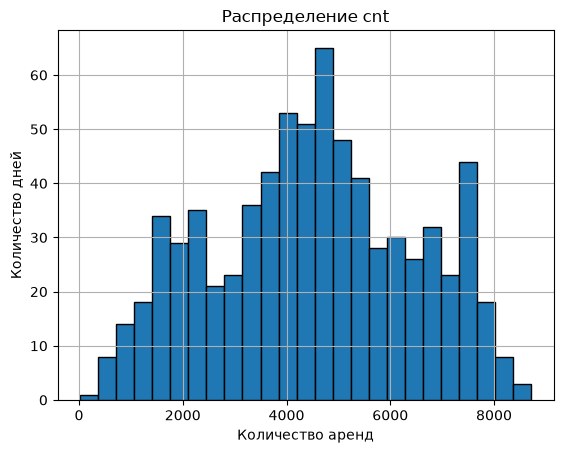

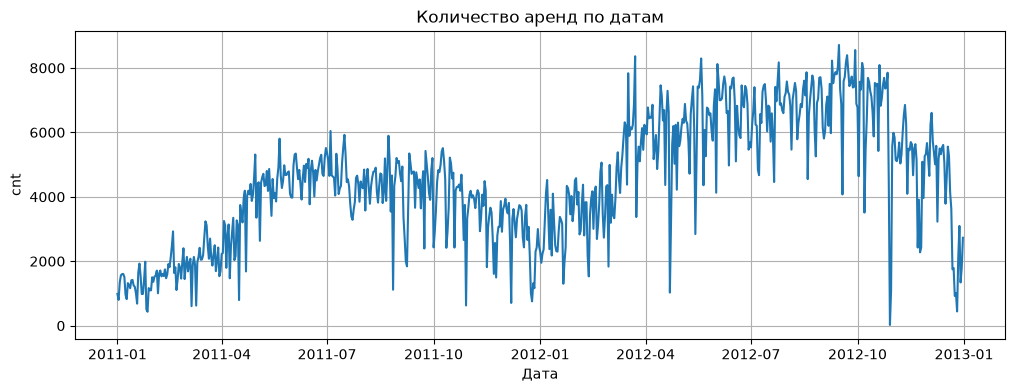

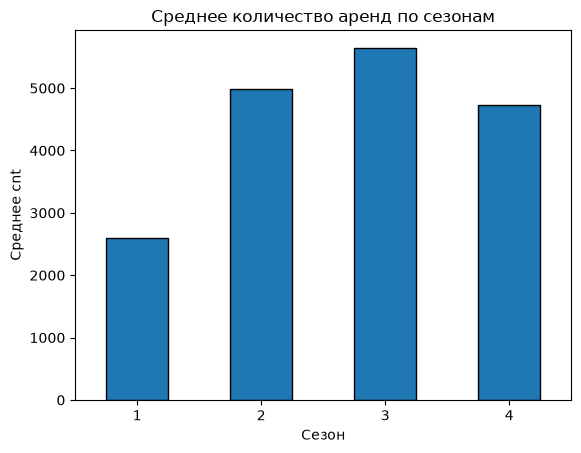

In [32]:
df["cnt"].hist(bins=25, edgecolor="black")
plt.title("Распределение cnt")
plt.xlabel("Количество аренд")
plt.ylabel("Количество дней")
plt.show()

plt.figure(figsize=(12, 4))
plt.plot(df["dteday"], df["cnt"])
plt.title("Количество аренд по датам")
plt.xlabel("Дата")
plt.ylabel("cnt")
plt.grid()
plt.show()

df.groupby("season")["cnt"].mean().plot(kind="bar", edgecolor="black")
plt.title("Среднее количество аренд по сезонам")
plt.xlabel("Сезон")
plt.ylabel("Среднее cnt")
plt.xticks(rotation=0)
plt.show()

### Вывод по первичному исследованию

- 731 строка и 16 столбцов; данные за 2011-2012 годы
- пропусков и полных дубликатов нет
- $ cnt \in [22; 8714] $; $ \bar{cnt} \approx 4504 $.
- $ cnt = casual + registered $, поэтому `casual` и `registered` удалим
- `instant` - id строки; его юзать не будем

## Подготовка данных

создадим целевую переменную `y` и признаки `X`. Удалим `casual` и `registered`, так как из них напрямую получается `cnt`. `instant` и дату тоже использовать не будем.

In [15]:
y = df["cnt"]
X = df.drop(columns=["cnt", "casual", "registered", "instant", "dteday"])

X.head()

,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed
0,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446
1,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539
2,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309
3,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296
4,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900


### Разделение данных

перемешаем индексы и разделим данные на train и test в пропорции 80/20.

In [16]:
indices = np.random.default_rng(SEED).permutation(len(X))
split = int(len(X) * (1 - TEST_SIZE))

train_idx = indices[:split]
test_idx = indices[split:]

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()
y_train = y.iloc[train_idx].to_numpy()
y_test = y.iloc[test_idx].to_numpy()

### Категориальные признаки

применим `get_dummies`, чтобы модель не воспринимала номера сезонов, месяцев, дней недели и типов погоды как обычные числа. Каждая категория станет отдельным столбцом из 0 и 1.

In [17]:
cat_cols = ["season", "mnth", "weekday", "weathersit"]

X_train = pd.get_dummies(X_train, columns=cat_cols, dtype=int)
X_test = pd.get_dummies(X_test, columns=cat_cols, dtype=int)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print("train:", X_train.shape, y_train.shape)
print("test:", X_test.shape, y_test.shape)
X_train.head()

train: (584, 33) (584,)
test: (147, 33) (147,)


,yr,holiday,workingday,temp,atemp,hum,windspeed,season_1,season_2,season_3,...,weekday_0,weekday_1,weekday_2,weekday_3,weekday_4,weekday_5,weekday_6,weathersit_1,weathersit_2,weathersit_3
412,1,0,1,0.343333,0.351629,0.634583,0.205846,1,0,0,...,0,0,0,0,0,1,0,1,0,0
52,0,0,1,0.182222,0.186033,0.577778,0.195683,1,0,0,...,0,0,1,0,0,0,0,1,0,0
374,1,0,1,0.308696,0.318826,0.646522,0.187552,1,0,0,...,0,0,1,0,0,0,0,1,0,0
695,1,0,1,0.313333,0.339004,0.535417,0.046650,0,0,0,...,0,1,0,0,0,0,0,1,0,0
663,1,0,1,0.550000,0.529688,0.800417,0.124375,0,0,0,...,0,0,0,0,1,0,0,0,1,0


### Вывод

- создали `X` и `y` и убрали столбцы с утечкой
- получили 584 объекта в train и 147 в test
- после `get_dummies` получили 33 числовых признака

### Обучение модели

импортируем класс и обучим модель на `X_train` и `y_train`.

In [ ]:
from lin_reg import LinearRegression

model = LinearRegression(learning_rate=0.01, epochs=1000)
model.fit(X_train, y_train)

print("начальный loss:", model.loss_history[0])
print("конечный loss:", model.loss_history[-1])

начальный loss: 24366537.202054795
конечный loss: 666838.1214032889


### График loss

по графику проверим, уменьшается ли ошибка во время обучения.

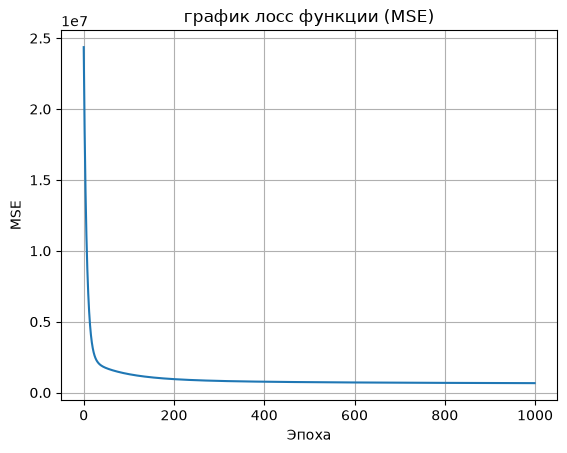

In [ ]:
plt.plot(model.loss_history)
plt.title("график лосс функции (MSE)")
plt.xlabel("Эпоха")
plt.ylabel("MSE")
plt.grid()
plt.show()

### Оценка модели

получим предсказания на **тестовую** выборку и посчитаем MAE, RMSE и $R^2$

In [29]:
y_pred = model.predict(X_test)

mae = np.mean(np.abs(y_test - y_pred))
rmse = np.sqrt(np.mean((y_test - y_pred) ** 2))
r2 = 1 - np.sum((y_test - y_pred) ** 2) / np.sum((y_test - y_test.mean()) ** 2)

print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"R^2: {r2:.3f}")

MAE: 646.24
RMSE: 844.90
R^2: 0.805


### Подумаем, что же значат эти числа

**MAE** - средняя абсолютная ошибка:

$$ MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| $$

MAE = 646 означает, что модель в среднем ошибается примерно на 646 аренд

**RMSE** - корень из средней квадратичной ошибки:

$$ RMSE = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2} $$

RMSE = 845 сильнее учитывает большие ошибки. Он выше MAE, значит у модели есть отдельные крупные промахи...

**$R^2$** показывает, какую часть разброса целевой переменной объясняет модель:

$$ R^2 = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2} $$

$R^2 = 0.805$ означает, что модель объясняет около 80.5% разброса `cnt`. Значение 1 соответствует идеальной модели, 0 - предсказанию среднего (baseline)

### Baseline

в качестве baseline всегда будем предсказывать среднее значение `y_train`. Среднее берём только по train, чтобы не использовать информацию из test.

In [31]:
baseline_pred = np.full(y_test.shape, y_train.mean()) # np array заполненный средним значением по train

baseline_mae = np.mean(np.abs(y_test - baseline_pred))
baseline_rmse = np.sqrt(np.mean((y_test - baseline_pred) ** 2))
baseline_r2 = 1 - np.sum((y_test - baseline_pred) ** 2) / np.sum((y_test - y_test.mean()) ** 2) # очев будет оч близкое к 0

comparison = pd.DataFrame({
    "MAE": [mae, baseline_mae],
    "RMSE": [rmse, baseline_rmse],
    "R^2": [r2, baseline_r2]
}, index=["My Cool LinReg", "Baseline"])

comparison.round(3)

,MAE,RMSE,R^2
My Cool LinReg,646.240,844.901,0.805
Baseline,1591.668,1922.266,-0.008


### Вывод

- линейная регрессия ошибается в среднем на 646 аренд, baseline - на 1592
- RMSE модели тоже заметно ниже: 845 против 1922
- модель объясняет около 80.5% разброса `cnt`, поэтому она намного лучше простого среднего
- $R^2$ baseline немного меньше нуля, потому что он использует среднее train, которое отличается от среднего test

В общем моя модель имеет смысл

### Графики предсказаний

на первом графике точки должны быть ближе к красной диагонали. На втором остатки должны располагаться вокруг нуля без явного рисунка.

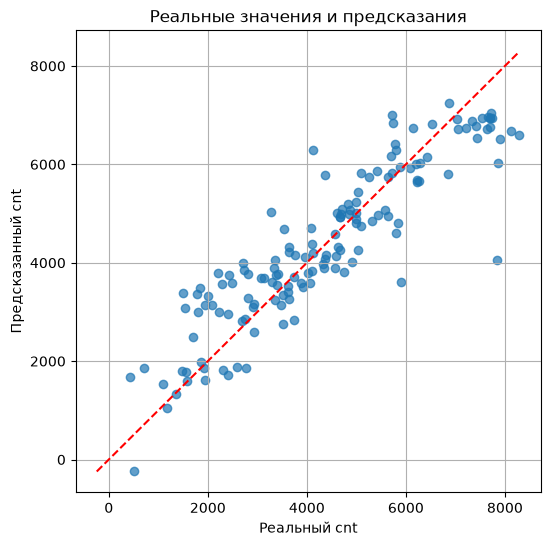

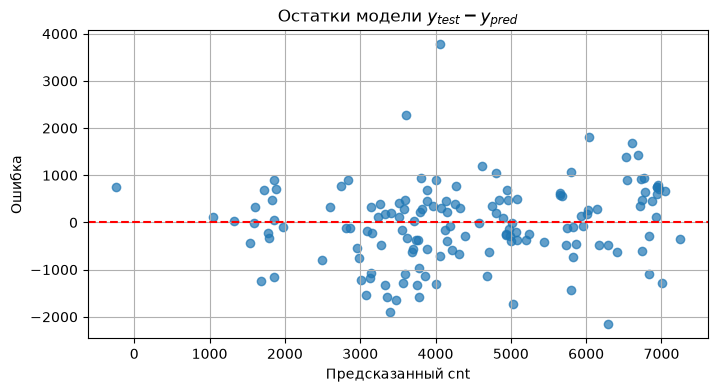

In [35]:
limits = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]

plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.7)
plt.plot(limits, limits, "r--")
plt.title("Реальные значения и предсказания")
plt.xlabel("Реальный cnt")
plt.ylabel("Предсказанный cnt")
plt.grid()
plt.show()

residuals = y_test - y_pred

plt.figure(figsize=(8, 4))
plt.scatter(y_pred, residuals, alpha=0.7)
plt.axhline(0, color="red", linestyle="--")
plt.title("Остатки модели $ y_{test} - y_{pred} $")
plt.xlabel("Предсказанный cnt")
plt.ylabel("Ошибка")
plt.grid()
plt.show()

# Часть B. Логистическая регрессия

## Загрузка и первичное исследование данных

ну судя по всему одна строка - один пассажир; `Transported` - целевая переменная

In [37]:
import pandas as pd
import matplotlib.pyplot as plt

df_log = pd.read_csv("data/train.csv")

print("size:", df_log.shape)
df_log.head()

size: (8693, 14)


,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


### Структура, типы и пропуски

посмотрим типы данных и количество пропусков

In [38]:
df_log.info()
df_log.isna().sum().sort_values(ascending=False)

<class 'pandas.DataFrame'>
RangeIndex: 8693 entries, 0 to 8692
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   PassengerId   8693 non-null   str    
 1   HomePlanet    8492 non-null   str    
 2   CryoSleep     8476 non-null   object 
 3   Cabin         8494 non-null   str    
 4   Destination   8511 non-null   str    
 5   Age           8514 non-null   float64
 6   VIP           8490 non-null   object 
 7   RoomService   8512 non-null   float64
 8   FoodCourt     8510 non-null   float64
 9   ShoppingMall  8485 non-null   float64
 10  Spa           8510 non-null   float64
 11  VRDeck        8505 non-null   float64
 12  Name          8493 non-null   str    
 13  Transported   8693 non-null   bool   
dtypes: bool(1), float64(6), object(2), str(5)
memory usage: 891.5+ KB


CryoSleep       217
ShoppingMall    208
VIP             203
HomePlanet      201
Name            200
Cabin           199
VRDeck          188
Spa             183
FoodCourt       183
Destination     182
RoomService     181
Age             179
PassengerId       0
Transported       0
dtype: int64

In [39]:
df_log.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,8514.0,28.827930,14.489021,0.0,19.0,27.0,38.0,79.0
RoomService,8512.0,224.687617,666.717663,0.0,0.0,0.0,47.0,14327.0
FoodCourt,8510.0,458.077203,1611.489240,0.0,0.0,0.0,76.0,29813.0
ShoppingMall,8485.0,173.729169,604.696458,0.0,0.0,0.0,27.0,23492.0
Spa,8510.0,311.138778,1136.705535,0.0,0.0,0.0,59.0,22408.0
VRDeck,8505.0,304.854791,1145.717189,0.0,0.0,0.0,46.0,24133.0


### Баланс классов и графики

проверим распределение `Transported` и посмотрим долю перемещённых пассажиров по планетам.

In [40]:
print("Дубликаты:", df_log.duplicated().sum())
df_log["Transported"].value_counts(normalize=True)

Дубликаты: 0


Transported
True     0.503624
False    0.496376
Name: proportion, dtype: float64

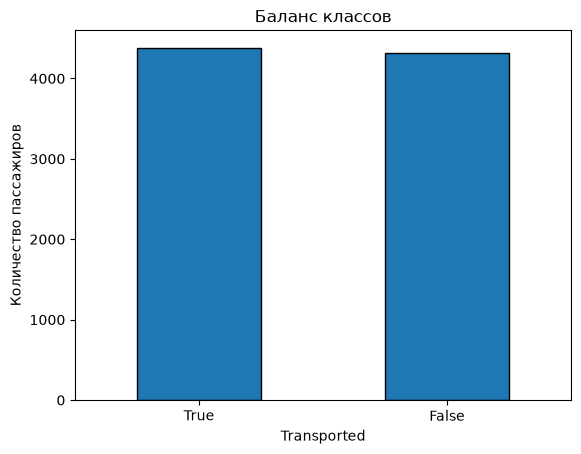

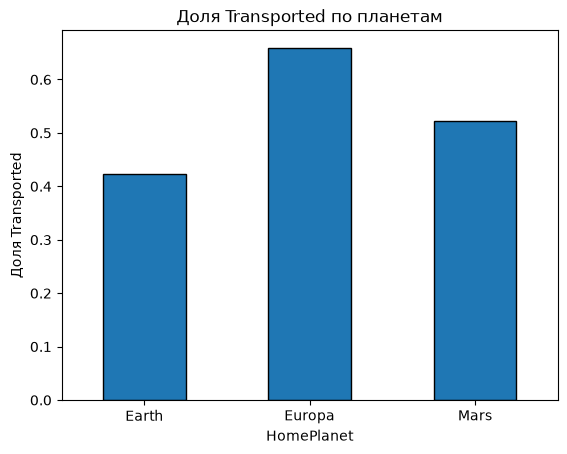

In [41]:
df_log["Transported"].value_counts().plot(kind="bar", edgecolor="black")
plt.title("Баланс классов")
plt.xlabel("Transported")
plt.ylabel("Количество пассажиров")
plt.xticks(rotation=0)
plt.show()

df_log.groupby("HomePlanet")["Transported"].mean().plot(kind="bar", edgecolor="black")
plt.title("Доля Transported по планетам")
plt.xlabel("HomePlanet")
plt.ylabel("Доля Transported")
plt.xticks(rotation=0)
plt.show()

### Вывод

- в данных 8693 пассажира и 14 столбцов
- целевая переменная почти сбалансирована: 50.4% `True` и 49.6% `False`
- полных дубликатов нет
- пропуски есть почти во всех признаках, позже их нужно заполнить
- расходы сильно скошены: у большинства значения около нуля, но есть очень большие значения
- категориальные признаки позже закодируем через `get_dummies`

## Подготовка данных

`Transported` запишем в $y$, остальные признаки - в $X$. `Name` и `PassengerId` уберём: это почти уникальные идентификаторы.

`Cabin` кстати имеет вид `палуба/номер/сторона`, поэтому разделим его на три отдельных признака.

In [42]:
import numpy as np

y = df_log["Transported"].astype(int)
X = df_log.drop(columns=["Transported", "Name", "PassengerId"])

cabin = X["Cabin"].str.split("/", expand=True   )
X["Deck"] = cabin[0]
X["CabinNum"] = pd.to_numeric(cabin[1])
X["Side"] = cabin[2]
X = X.drop(columns="Cabin")

print("X:", X.shape)
print("y:", y.shape)
X.head()

X: (8693, 13)
y: (8693,)


,HomePlanet,CryoSleep,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Deck,CabinNum,Side
0,Europa,False,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,B,0.0,P
1,Earth,False,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,F,0.0,S
2,Europa,False,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,A,0.0,S
3,Europa,False,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,A,0.0,S
4,Earth,False,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,F,1.0,S


### Разделение на train и test

сначала разделим данные, а уже потом найдём медианы и моды только по `train`. Так информация из `test` не попадёт в обучение.

In [43]:
SEED = 67
TEST_SIZE = 0.2

indices = np.random.default_rng(SEED).permutation(len(X))
split = int(len(X) * (1 - TEST_SIZE))
train_idx, test_idx = indices[:split], indices[split:]

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()
y_train = y.iloc[train_idx].to_numpy()
y_test = y.iloc[test_idx].to_numpy()

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (6954, 13)
Test: (1739, 13)


### Обработка пропусков

числовые пропуски заполним медианой, категориальные - самым частым значением. Все значения берём только из `train`.

In [ ]:
num_cols = X_train.select_dtypes(include="number").columns
cat_cols = X_train.select_dtypes(exclude="number").columns

for col in num_cols:
    median = X_train[col].median()
    X_train[col] = X_train[col].fillna(median)
    X_test[col] = X_test[col].fillna(median)

for col in cat_cols:
    mode = X_train[col].mode()[0]
    X_train[col] = X_train[col].fillna(mode)
    X_test[col] = X_test[col].fillna(mode)

print("Пропусков в train:", X_train.isna().sum().sum()) # sum() отдельно по колонкам; sum() сложить в общее число
print("Пропусков в test:", X_test.isna().sum().sum())

Пропусков в train: 0
Пропусков в test: 0


### Категориальные признаки

`get_dummies` наш дорогой любимый

In [45]:
X_train = pd.get_dummies(X_train, columns=cat_cols, dtype=int)
X_test = pd.get_dummies(X_test, columns=cat_cols, dtype=int)
X_test = X_test.reindex(columns=X_train.columns, fill_value=0)

print("После get_dummies:", X_train.shape)
X_train.head()

После get_dummies: (6954, 27)


,Age,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,CabinNum,HomePlanet_Earth,HomePlanet_Europa,HomePlanet_Mars,...,Deck_A,Deck_B,Deck_C,Deck_D,Deck_E,Deck_F,Deck_G,Deck_T,Side_P,Side_S
3255,34.0,0.0,6229.0,0.0,2279.0,587.0,127.0,0,1,0,...,0,0,1,0,0,0,0,0,0,1
3751,38.0,0.0,0.0,0.0,0.0,0.0,658.0,1,0,0,...,0,0,0,0,0,0,1,0,1,0
151,32.0,0.0,0.0,0.0,0.0,0.0,24.0,1,0,0,...,0,0,0,0,0,0,1,0,1,0
5407,61.0,0.0,0.0,0.0,0.0,0.0,217.0,0,1,0,...,0,0,1,0,0,0,0,0,0,1
269,50.0,0.0,0.0,0.0,0.0,0.0,8.0,0,1,0,...,0,1,0,0,0,0,0,0,0,1


### Масштабирование чисел

возраст и расходы имеют разный масштаб. Приведём числовые признаки к среднему 0 и стандартному отклонению 1, чтобы градиентный спуск обучался стабильнее.

In [ ]:
means = X_train[num_cols].mean()
stds = X_train[num_cols].std().replace(0, 1)

X_train[num_cols] = (X_train[num_cols] - means) / stds
X_test[num_cols] = (X_test[num_cols] - means) / stds

print("Итоговый train:", X_train.shape)
print("Итоговый test:", X_test.shape)

Итоговый train: (6954, 27)
Итоговый test: (1739, 27)


## Логистическая регрессия

### `fit`

сначала считаем лин. комбинацию признаков:

$$z = Xw + b$$

сигмоида переводит её $ p \in (0;1) $ - вероятность:

$$p = \sigma(z) = \frac{1}{1 + e^{-z}}$$

ошибку считаем через BCE:

$$L = -\frac{1}{n}\sum_{i=1}^{n} \left[y_i\ln(p_i) + (1-y_i)\ln(1-p_i)\right]$$

её градиенты по весам и смещению:

$$\nabla_w L = \frac{1}{n}X^T(p-y), \qquad \nabla_b L = \frac{1}{n}\sum_{i=1}^{n}(p_i-y_i)$$

после этого обновляем параметры в сторону уменьшения ошибки:

$$w \leftarrow w - \eta\nabla_w L, \qquad b \leftarrow b - \eta\nabla_b L$$

так повторяется каждую эпоху, значение $L$ сохраняется в `loss_history`.

### Обучение модели

In [51]:
from log_reg import LogisticRegression

model = LogisticRegression(learning_rate=0.1, epochs=1000)
model.fit(X_train, y_train)

print("Начальный BCE:", model.loss_history[0])
print("Конечный BCE:", model.loss_history[-1])

Начальный BCE: 0.6931471805599453
Конечный BCE: 0.4337430390348106


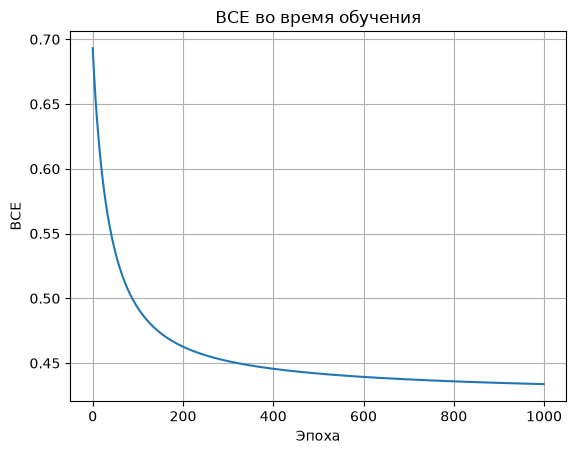

In [52]:
plt.plot(model.loss_history)
plt.title("BCE во время обучения")
plt.xlabel("Эпоха")
plt.ylabel("BCE")
plt.grid()
plt.show()

### Метрики на test

In [53]:
y_proba = model.predict_proba(X_test)
y_pred = model.predict(X_test)

tp = np.sum((y_test == 1) & (y_pred == 1))
tn = np.sum((y_test == 0) & (y_pred == 0))
fp = np.sum((y_test == 0) & (y_pred == 1))
fn = np.sum((y_test == 1) & (y_pred == 0))

accuracy = (tp + tn) / len(y_test)
precision = tp / (tp + fp)
recall = tp / (tp + fn)
f1 = 2 * precision * recall / (precision + recall)

safe_proba = np.clip(y_proba, 1e-15, 1 - 1e-15)
log_loss = -np.mean(y_test * np.log(safe_proba) + (1 - y_test) * np.log(1 - safe_proba))

metrics = pd.Series({
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1": f1,
    "LogLoss": log_loss
})
metrics.round(3)

Accuracy     0.771
Precision    0.771
Recall       0.778
F1           0.775
LogLoss      0.462
dtype: float64

In [55]:
confusion_matrix = pd.DataFrame(
    [[tn, fp], [fn, tp]],
    index=["really 0", "really 1"],
    columns=["predicted 0", "predicted 1"]
)
confusion_matrix

,predicted 0,predicted 1
really 0,656,203
really 1,195,685


### Что у меня получилось

- `Accuracy =   0.771` - модель правильно классифицировала 77.1% пассажиров
- `Precision =  0.771` - среди предсказанных `Transported = 1` верными оказались 77.1%
- `Recall =     0.778` - модель нашла 77.8% реально перемещённых пассажиров
- `F1 =         0.775` - precision и recall близки, сильного перекоса между ними нет
- `LogLoss =    0.462` - чем он меньше, тем точнее предсказанные вероятности

для сравнения, если всегда предсказывать вероятность $p=0.5$, то при любом правильном классе ошибка одного объекта равна:

$$-\ln(0.5) = \ln(2) \approx 0.693$$

поэтому `0.462 < 0.693` означает, что вероятности нашей модели информативнее постоянного ответа 50 на 50.

из 1739 пассажиров модель ошиблась на 398. Ошибки двух типов почти равны: `FP = 203`, `FN = 195`, поэтому модель не имеет заметного перекоса в один класс. BCE на test немного выше, чем на train (`0.462` против `0.434`) - это норм разница, сильного переобучения не видно.

### Majority baseline

baseline всегда предсказывает самый частый класс из `y_train`. Для LogLoss используем постоянную вероятность, равную доле класса 1 в train.

In [56]:
majority_class = int(y_train.mean() >= 0.5)
baseline_pred = np.full(len(y_test), majority_class)
baseline_proba = np.full(len(y_test), y_train.mean())

b_tp = np.sum((y_test == 1) & (baseline_pred == 1))
b_tn = np.sum((y_test == 0) & (baseline_pred == 0))
b_fp = np.sum((y_test == 0) & (baseline_pred == 1))
b_fn = np.sum((y_test == 1) & (baseline_pred == 0))

b_accuracy = (b_tp + b_tn) / len(y_test)
b_precision = b_tp / (b_tp + b_fp)
b_recall = b_tp / (b_tp + b_fn)
b_f1 = 2 * b_precision * b_recall / (b_precision + b_recall)
b_log_loss = -np.mean(
    y_test * np.log(baseline_proba)
    + (1 - y_test) * np.log(1 - baseline_proba)
)

baseline_metrics = pd.Series({
    "Accuracy": b_accuracy,
    "Precision": b_precision,
    "Recall": b_recall,
    "F1": b_f1,
    "LogLoss": b_log_loss
})

pd.DataFrame({"Моя LogReg": metrics, "Majority baseline": baseline_metrics}).T.round(3)

,Accuracy,Precision,Recall,F1,LogLoss
Моя LogReg,0.771,0.771,0.778,0.775,0.462
Majority baseline,0.506,0.506,1.000,0.672,0.693


### Итог

в train немного больше класса 1, поэтому baseline считает перемещёнными вообще всех пассажиров. Из-за этого его `Recall = 1`, но `Precision = 0.506`, а правильных ответов всего 50.6%. Значение F1 у него выглядит неплохо только потому, что он всегда выбирает положительный класс.

моя модель дала `Accuracy = 0.771` против `0.506` и `LogLoss = 0.462` против `0.693`. Значит модель действительно нашла зависимости в признаках и заметно лучше простого baseline.